## Analysis

This part runs on a laptop, no GPU needed. It reads the model's answers from
`../data/model_results.csv` (made by `run_model.ipynb`) and Bouma's data from
`../data/bouma1970_from_coates2021.csv`.

In [1]:
import numpy  as np
import pandas as pd
from IPython.display import Image

import figures      # the figures on the page
import fit_bouma    # the psychometric function used for Bouma's data
import stimuli      # the experiment's numbers

model = pd.read_csv("../data/model_results.csv")
bouma = pd.read_csv("../data/bouma1970_from_coates2021.csv")
print("model trials:", len(model))

model trials: 1200


### Proportion correct

In [2]:
model["spacing_deg"] = model["spacing"].map(stimuli.spacing_deg)      # NaN = no flankers
table = model.pivot_table(index="ecc_deg", columns=model["spacing_deg"].fillna(np.inf).round(2), values="correct")
table = table.rename(columns={np.inf: "alone"})
print("rows: target position (deg); columns: spacing, centre to centre (deg)")
print(table.round(2))

rows: target position (deg); columns: spacing, centre to centre (deg)
spacing_deg  0.29  0.58  1.17  2.34  4.68  alone
ecc_deg                                         
0            0.57  0.98  1.00  0.99   1.0    1.0
10           0.21  0.68  0.92  0.96   1.0    1.0


### What the wrong answers were

In [3]:
wrong = model[model["spacing"].notna() & ~model["correct"]]
for ecc, w in wrong.groupby("ecc_deg"):
  left  = (w["answer"] == w["inner_flanker"]).sum()     # inner = the flanker on the left
  right = (w["answer"] == w["outer_flanker"]).sum()
  print("%2d deg: %3d wrong, named a flanker %3d times (left %d, right %d)" % (ecc, len(w), left + right, left, right))

 0 deg:  46 wrong, named a flanker  46 times (left 7, right 39)
10 deg: 123 wrong, named a flanker 123 times (left 4, right 119)


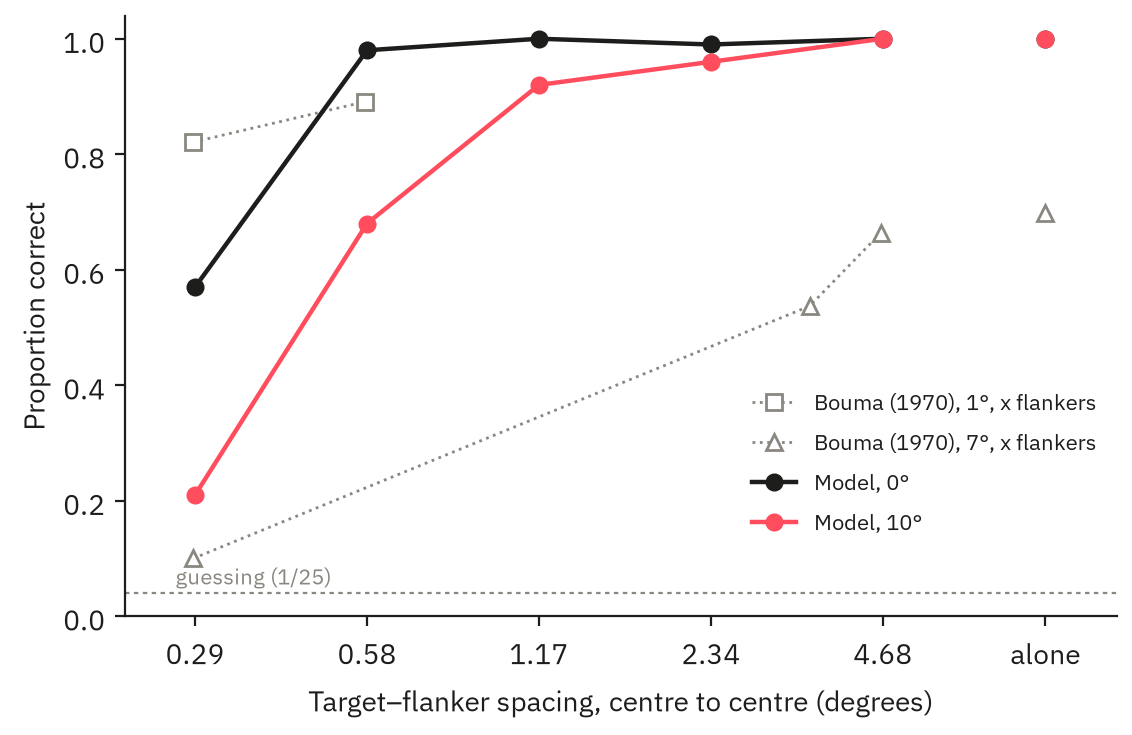

In [4]:
figures.results_figure("../img/vlm_results.png", model, bouma)
Image("../img/vlm_results.png", width=560)

### Critical spacing, as for Bouma's data

The same S-shaped curve as for Bouma's data (`fit_bouma.py`): proportion correct against
log spacing, from guessing (1/25) up to the level for a letter on its own. The critical
spacing is where the curve is 60%, 80% or 90% of the way up.

In [5]:
cutoffs = [0.6, 0.8, 0.9]
for ecc, d in model.groupby("ecc_deg"):
  x      = np.log(d["spacing_deg"].fillna(np.inf))
  counts = d.assign(x=x).groupby("x")["correct"].sum()
  A, m, w = fit_bouma.fit(counts.index.to_numpy(), counts.to_numpy()).x
  spacing = [fit_bouma.critical_spacing(m, w, c) for c in cutoffs]
  print("model %2d deg: critical spacing %s deg" % (ecc, " / ".join("%.2f" % s for s in spacing)))

human = pd.read_csv("../data/bouma1970_critical_spacing.csv")
for ecc, d in human[human["cutoff"].isin(cutoffs)].groupby("ecc_deg"):
  print("Bouma %3d deg: critical spacing %s deg" % (ecc, " / ".join("%.2f" % s for s in d["critical_spacing_deg"])))

model  0 deg: critical spacing 0.30 / 0.36 / 0.42 deg
model 10 deg: critical spacing 0.57 / 0.83 / 1.13 deg
Bouma   2 deg: critical spacing 0.34 / 0.65 / 1.11 deg
Bouma   3 deg: critical spacing 0.61 / 1.11 / 1.81 deg
Bouma   5 deg: critical spacing 1.15 / 2.19 / 3.72 deg
Bouma   7 deg: critical spacing 1.80 / 3.42 / 5.84 deg


### A letter on its own

In [6]:
alone = model[model["spacing"].isna()].groupby("ecc_deg")["correct"].mean()
print("model: ", ", ".join("%d deg %.2f" % (e, p) for e, p in alone.items()))
unflanked = bouma[bouma["gap_slots"].isna()].set_index("ecc_deg")["p_correct"]
print("Bouma: ", ", ".join("%g deg %.2f" % (e, p) for e, p in unflanked.items()))

model:  0 deg 1.00, 10 deg 1.00
Bouma:  3 deg 0.98, 5 deg 0.82, 7 deg 0.70, 10.5 deg 0.44


## Run it yourself

All of the code is in `chapters/crowding/code/`:

1. `stimuli.py` draws the images (and Figures 5 and 6).
2. `run_model.ipynb` asks the model about every image. It needs a GPU (Colab, about 2 minutes).
3. `analysis.ipynb`, this notebook, makes the numbers and Figure 7.
4. `extract_bouma_from_coates.py` and `fit_bouma.py` read Bouma's data from Coates et al. (2021) and fit it.

Things to try: put the target on the left as well, to tell "outer" from "right"; add more
positions between 0 and 10 degrees; use Bouma's "x" flankers instead of random letters.